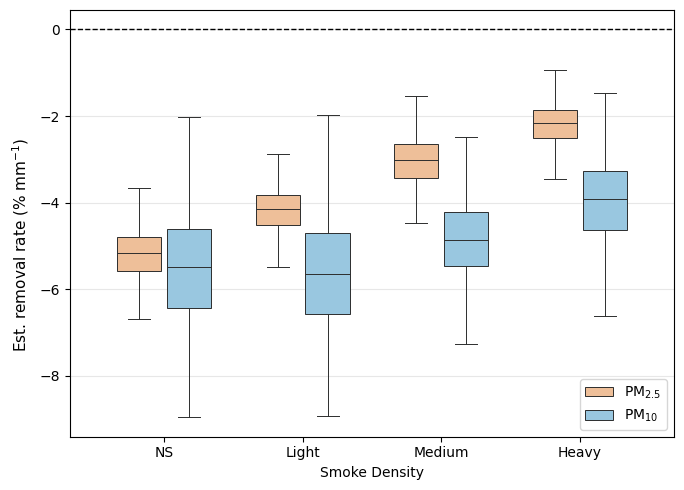

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PM25_DARK, PM10_DARK = "#D55E00", "#0072B2"
PM25_LIGHT50, PM10_LIGHT50 = "#EEBF99", "#99C7E0"

box_and_whisker_boundary = "#2C2D2D"

label_map = {0: "NS", 1: "Light", 2: "Medium", 3: "Heavy"}

pm10 = pd.read_csv(
    r"\results\pm10\PM10_smoke_bootstrap_results_overall.csv"
)
pm25 = pd.read_csv(
    r"\results\pm25\PM25_smoke_bootstrap_results_overall.csv"
)

pm10["pollutant"] = "PM10"
pm25["pollutant"] = "PM2.5"

plot_df = pd.concat([pm25, pm10], ignore_index=True)
plot_df = plot_df.dropna(subset=["Density", "theta"]).copy()

densities = sorted(plot_df["Density"].unique())

data_pm25 = [
    plot_df.loc[
        (plot_df["Density"] == d) & (plot_df["pollutant"] == "PM2.5"),
        "theta"
    ].values
    for d in densities
]

data_pm10 = [
    plot_df.loc[
        (plot_df["Density"] == d) & (plot_df["pollutant"] == "PM10"),
        "theta"
    ].values
    for d in densities
]

x = np.arange(len(densities))
width = 0.32
gap = 0.18

fig, ax = plt.subplots(figsize=(7, 5))

bp1 = ax.boxplot(
    data_pm25,
    positions=x - gap,
    widths=width,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor=PM25_LIGHT50, edgecolor=box_and_whisker_boundary, linewidth=0.7),
    whiskerprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    capprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    medianprops=dict(color=box_and_whisker_boundary, linewidth=0.7)
)

bp2 = ax.boxplot(
    data_pm10,
    positions=x + gap,
    widths=width,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor=PM10_LIGHT50, edgecolor=box_and_whisker_boundary, linewidth=0.7),
    whiskerprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    capprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
    medianprops=dict(color=box_and_whisker_boundary, linewidth=0.7)
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels([label_map[d] for d in densities])

ax.set_xlabel("Smoke Density")
fig.supylabel(r"Est. removal rate (% mm$^{-1}$)", fontsize=11, x=0.03)
# ax.set_title("Bootstrapped theta by smoke density")

ax.legend(
    [bp1["boxes"][0], bp2["boxes"][0]],
    [r"PM$_{2.5}$", r"PM$_{10}$"],
    # title="APCP: Total",
    loc="lower right",
    frameon=True
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    r"\figures\removal_by_smoke_overall.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

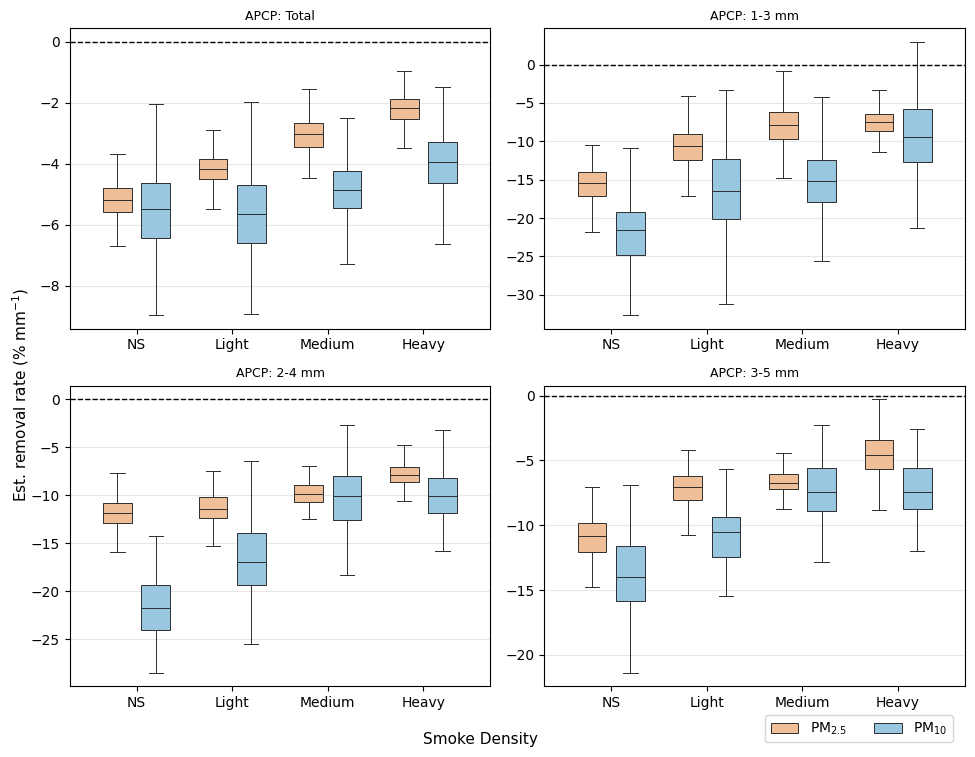

In [6]:
PM25_DARK, PM10_DARK = "#D55E00", "#0072B2"
PM25_LIGHT50, PM10_LIGHT50 = "#EEBF99", "#99C7E0"

box_and_whisker_boundary = "#2C2D2D"

label_map = {0: "NS", 1: "Light", 2: "Medium", 3: "Heavy"}

file_sets = {
    "Total": {
        "pm10": r"\results\pm10\PM10_smoke_bootstrap_results_overall.csv",
        "pm25": r"\results\pm25\PM25_smoke_bootstrap_results_overall.csv",
    },
    "1-3 mm": {
        "pm10": r"\results\pm10\PM10_smoke_bootstrap_results_1_3.csv",
        "pm25": r"\results\pm25\PM25_smoke_bootstrap_results_1_3.csv",
    },
    "2-4 mm": {
        "pm10": r"\results\pm10\PM10_smoke_bootstrap_results_2_4.csv",
        "pm25": r"\results\pm25\PM25_smoke_bootstrap_results_2_4.csv",
    },
    "3-5 mm": {
        "pm10": r"\results\pm10\PM10_smoke_bootstrap_results_3_5.csv",
        "pm25": r"\results\pm25\PM25_smoke_bootstrap_results_3_5.csv",
    },
}

width = 0.30
gap = 0.20

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey=False)
axes = axes.flatten()

legend_handles = None

for ax, (apcp_label, paths) in zip(axes, file_sets.items()):

    pm10 = pd.read_csv(paths["pm10"])
    pm25 = pd.read_csv(paths["pm25"])

    pm10["pollutant"] = "PM10"
    pm25["pollutant"] = "PM2.5"

    plot_df = pd.concat([pm25, pm10], ignore_index=True)
    plot_df = plot_df.dropna(subset=["Density", "theta"]).copy()

    densities = sorted(plot_df["Density"].unique())

    data_pm25 = [
        plot_df.loc[
            (plot_df["Density"] == d) & (plot_df["pollutant"] == "PM2.5"),
            "theta"
        ].values
        for d in densities
    ]

    data_pm10 = [
        plot_df.loc[
            (plot_df["Density"] == d) & (plot_df["pollutant"] == "PM10"),
            "theta"
        ].values
        for d in densities
    ]

    x = np.arange(len(densities))

    bp1 = ax.boxplot(
        data_pm25,
        positions=x - gap,
        widths=width,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(
            facecolor=PM25_LIGHT50,
            edgecolor=box_and_whisker_boundary,
            linewidth=0.7
        ),
        whiskerprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
        capprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
        medianprops=dict(color=box_and_whisker_boundary, linewidth=0.7)
    )

    bp2 = ax.boxplot(
        data_pm10,
        positions=x + gap,
        widths=width,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(
            facecolor=PM10_LIGHT50,
            edgecolor=box_and_whisker_boundary,
            linewidth=0.7
        ),
        whiskerprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
        capprops=dict(color=box_and_whisker_boundary, linewidth=0.7),
        medianprops=dict(color=box_and_whisker_boundary, linewidth=0.7)
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_xticks(x)
    ax.set_xticklabels([label_map[d] for d in densities])

    ax.set_title(f"APCP: {apcp_label}", fontsize=9)
    ax.grid(axis="y", alpha=0.3)

    legend_handles = [bp1["boxes"][0], bp2["boxes"][0]]

fig.supxlabel("Smoke Density", y=0.06, fontsize=11)

fig.supylabel(r"Est. removal rate (% mm$^{-1}$)", fontsize=11, x=0.03)

fig.legend(
    legend_handles,
    [r"PM$_{2.5}$", r"PM$_{10}$"],
    loc="lower right",
    bbox_to_anchor=(0.98, 0.057),
    frameon=True,
    ncol=2
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    r"C:\Users\dneupane\PycharmProjects\DMLImplementation\huber_plots\FIGURES\removal_by_smoke_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()